# AI CAPSTONE PROJECT – TRAFFIC SIGN DETECTION AND CLASSIFICATION

**Project ID:** PRAICP-1002-TrafSignDetc  
**Project Category:** Artificial Intelligence / Computer Vision  
**Project Type:** Image Classification  
**Proposed Algorithm:** Convolutional Neural Network (CNN)  
**Development Environment:** Google Colab  
**Programming Language:** Python

---

## 1. Project Overview

Traffic signs play an important role in road safety by communicating traffic regulations, warnings, and directions to drivers.

The objective of this project is to develop a machine learning model capable of recognizing and classifying different traffic signs from images.

The project involves image preprocessing, training a classification model, evaluating its performance, and predicting traffic sign categories from new images.

## 2. Problem Statement

Develop a machine learning-based traffic sign classification system that can identify the category of a traffic sign from an input image.

The dataset contains directories of images representing different traffic sign categories.

The model must learn meaningful visual features from these images and classify them into their corresponding traffic sign categories.


## 3. Business Objectives

- Automate the identification and classification of traffic signs.
- Reduce dependence on manual traffic sign image classification.
- Develop a computer vision model that recognizes different traffic sign categories.
- Evaluate model performance on unseen images.
- Explore the potential application of traffic sign recognition in intelligent transportation systems.

## 4. Technical Objectives

1. Load and understand the traffic sign image dataset.
2. Perform exploratory data analysis (EDA).
3. Preprocess images through resizing and normalization.
4. Prepare training, validation, and testing datasets.
5. Design and train a Convolutional Neural Network (CNN).
6. Evaluate the model using classification metrics.
7. Improve model performance through experimentation.
8. Predict traffic sign categories for unseen images.

## 5. Proposed Methodology

**Step 1 – Dataset Collection:** Load the traffic sign images from the provided dataset.

**Step 2 – Exploratory Data Analysis:** Examine class distributions, image dimensions, and sample images.

**Step 3 – Image Preprocessing:** Resize images, normalize pixel values, and prepare class labels.

**Step 4 – Dataset Splitting:** Prepare training, validation, and testing data while avoiding data leakage.

**Step 5 – CNN Model Development:** Build a CNN using convolutional, pooling, and dense layers.

**Step 6 – Model Training:** Train the model and monitor training and validation performance.

**Step 7 – Model Evaluation:** Evaluate accuracy, precision, recall, F1-score, and confusion matrix.

**Step 8 – Prediction:** Test the trained model using previously unseen traffic sign images.

## 6. Technology Stack

| Component | Technology |
|---|---|
| Programming | Python |
| Development Platform | Google Colab |
| Deep Learning | TensorFlow / Keras |
| Image Processing | OpenCV / Pillow |
| Numerical Computing | NumPy |
| Data Analysis | Pandas |
| Visualization | Matplotlib / Seaborn |
| Model Architecture | CNN |
| Hardware Acceleration | GPU |

## 7. Expected Outcome

The expected outcome is a trained CNN-based traffic sign classification model capable of predicting traffic sign categories from input images.

The project will include performance evaluation, visualizations, and sample predictions to demonstrate the model's classification capabilities.

Actual model performance and the number of supported traffic sign classes will be determined after dataset inspection and training.

## 8. Project Deliverables

- Google Colab notebook containing the complete workflow.
- Dataset analysis and visualizations.
- Trained CNN classification model.
- Model performance evaluation.
- Sample traffic sign predictions.
- Final project summary and conclusions.

In [1]:
import zipfile
import os

with zipfile.ZipFile("/content/drive/MyDrive/AI_Capstone_Projects/PRAICP-1002-TrafSignDetc.zip", "r") as zip_ref:
  zip_ref.extractall("/content/drive/MyDrive/AI_Capstone_Projects")

print("Dataset Extracted Successfully")

Dataset Extracted Successfully


In [2]:
print("Extracted Dataset Contents:")
print(os.listdir("/content/drive/MyDrive/AI_Capstone_Projects"))

Extracted Dataset Contents:
['PRAICP-1002-TrafSignDetc.zip', 'Meta.csv', 'Meta', 'Test.csv', 'Test', 'Train.csv', 'Train', 'meta', 'test', 'train']


## 2. Dataset Understanding

The traffic sign dataset contains training and testing images along with CSV files containing image-related information.

**Objectives:**
- Understand the dataset structure.
- Identify the number of training and testing images.
- Examine the dataset features and target labels.
- Identify the number of traffic sign classes.
- Check for missing values and duplicate records.

This analysis will help us prepare the dataset for CNN model training.

In [3]:
import pandas as pd

train_df = pd.read_csv("/content/drive/MyDrive/AI_Capstone_Projects/Train.csv")
train_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [4]:
test_df = pd.read_csv("/content/drive/MyDrive/AI_Capstone_Projects/Test.csv")
test_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


In [5]:
meta_df = pd.read_csv("/content/drive/MyDrive/AI_Capstone_Projects/Meta.csv")
meta_df.head()

,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22


In [6]:
print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)
print("Meta Shape:", meta_df.shape)

Train Shape: (39209, 8)
Test Shape: (12630, 8)
Meta Shape: (43, 5)


### 2.1 Data Quality and Target Class Analysis

In this section, we will:

1. Check missing values in the training dataset.
2. Check duplicate records.
3. Identify the number of unique traffic sign classes.
4. Examine the distribution of images across classes.

This helps us understand dataset quality and potential class imbalance before preprocessing.

In [7]:
print("Missing Values:")
print(train_df.isnull().sum())

print("\nDuplicate Records:", train_df.duplicated().sum())

print("\nNumber of Classes:", train_df["ClassId"].nunique())

print("\nClass Distribution:")
print(train_df["ClassId"].value_counts().sort_index())

Missing Values:
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Duplicate Records: 0

Number of Classes: 43

Class Distribution:
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240
Name: count, dtype: int64


### 2.2 Traffic Sign Class Distribution

The training dataset contains 43 traffic sign categories.

The number of images differs across classes, indicating class imbalance.

We will visualize the number of training images in each category to understand the distribution before CNN model development.

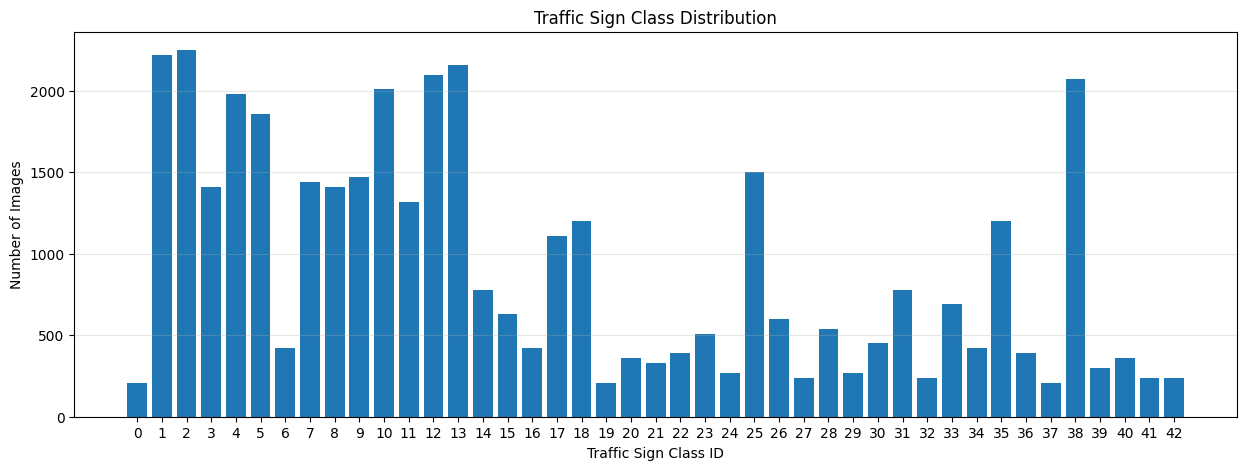

In [8]:
import matplotlib.pyplot as plt

class_counts = train_df["ClassId"].value_counts().sort_index()

plt.figure(figsize=(15, 5))

plt.bar(class_counts.index, class_counts.values)

plt.title("Traffic Sign Class Distribution")
plt.xlabel("Traffic Sign Class ID")
plt.ylabel("Number of Images")
plt.xticks(range(43))
plt.grid(axis="y", alpha=0.3)

plt.show()

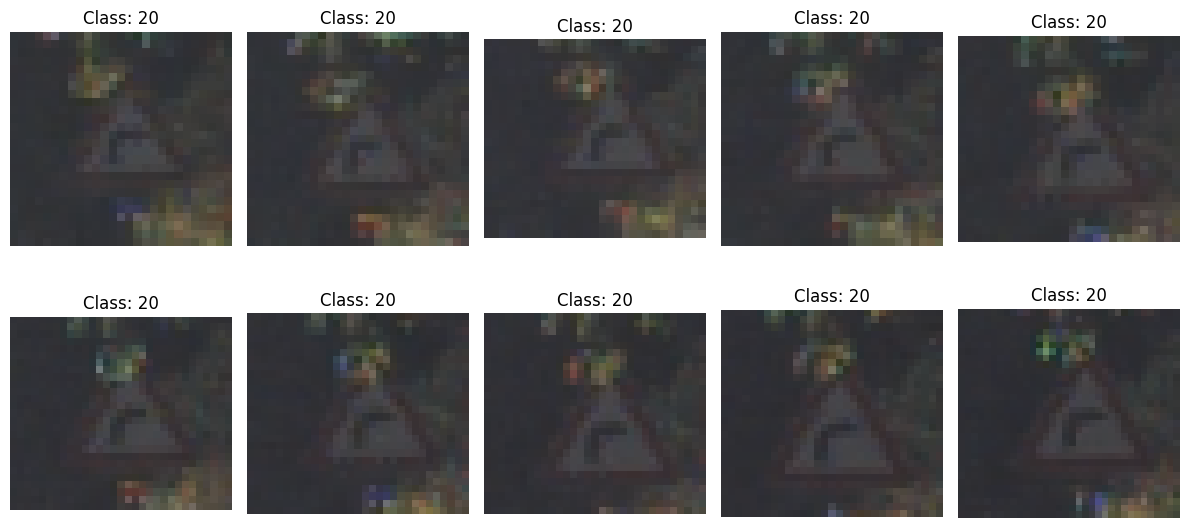

In [9]:
from PIL import Image
import matplotlib.pyplot as plt
import os

base_path = "/content/drive/MyDrive/AI_Capstone_Projects"

plt.figure(figsize=(12, 6))

for i in range(10):
    image_path = os.path.join(
        base_path,
        train_df.iloc[i]["Path"]
    )

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Class: {train_df.iloc[i]['ClassId']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 2.3 Visualization of Different Traffic Sign Classes

The dataset contains 43 traffic sign categories.

In this section, one sample image from each class will be displayed to understand the visual differences between traffic signs, including their shapes, colors, symbols, and image quality.

This visualization helps us understand the image classification problem before CNN preprocessing.

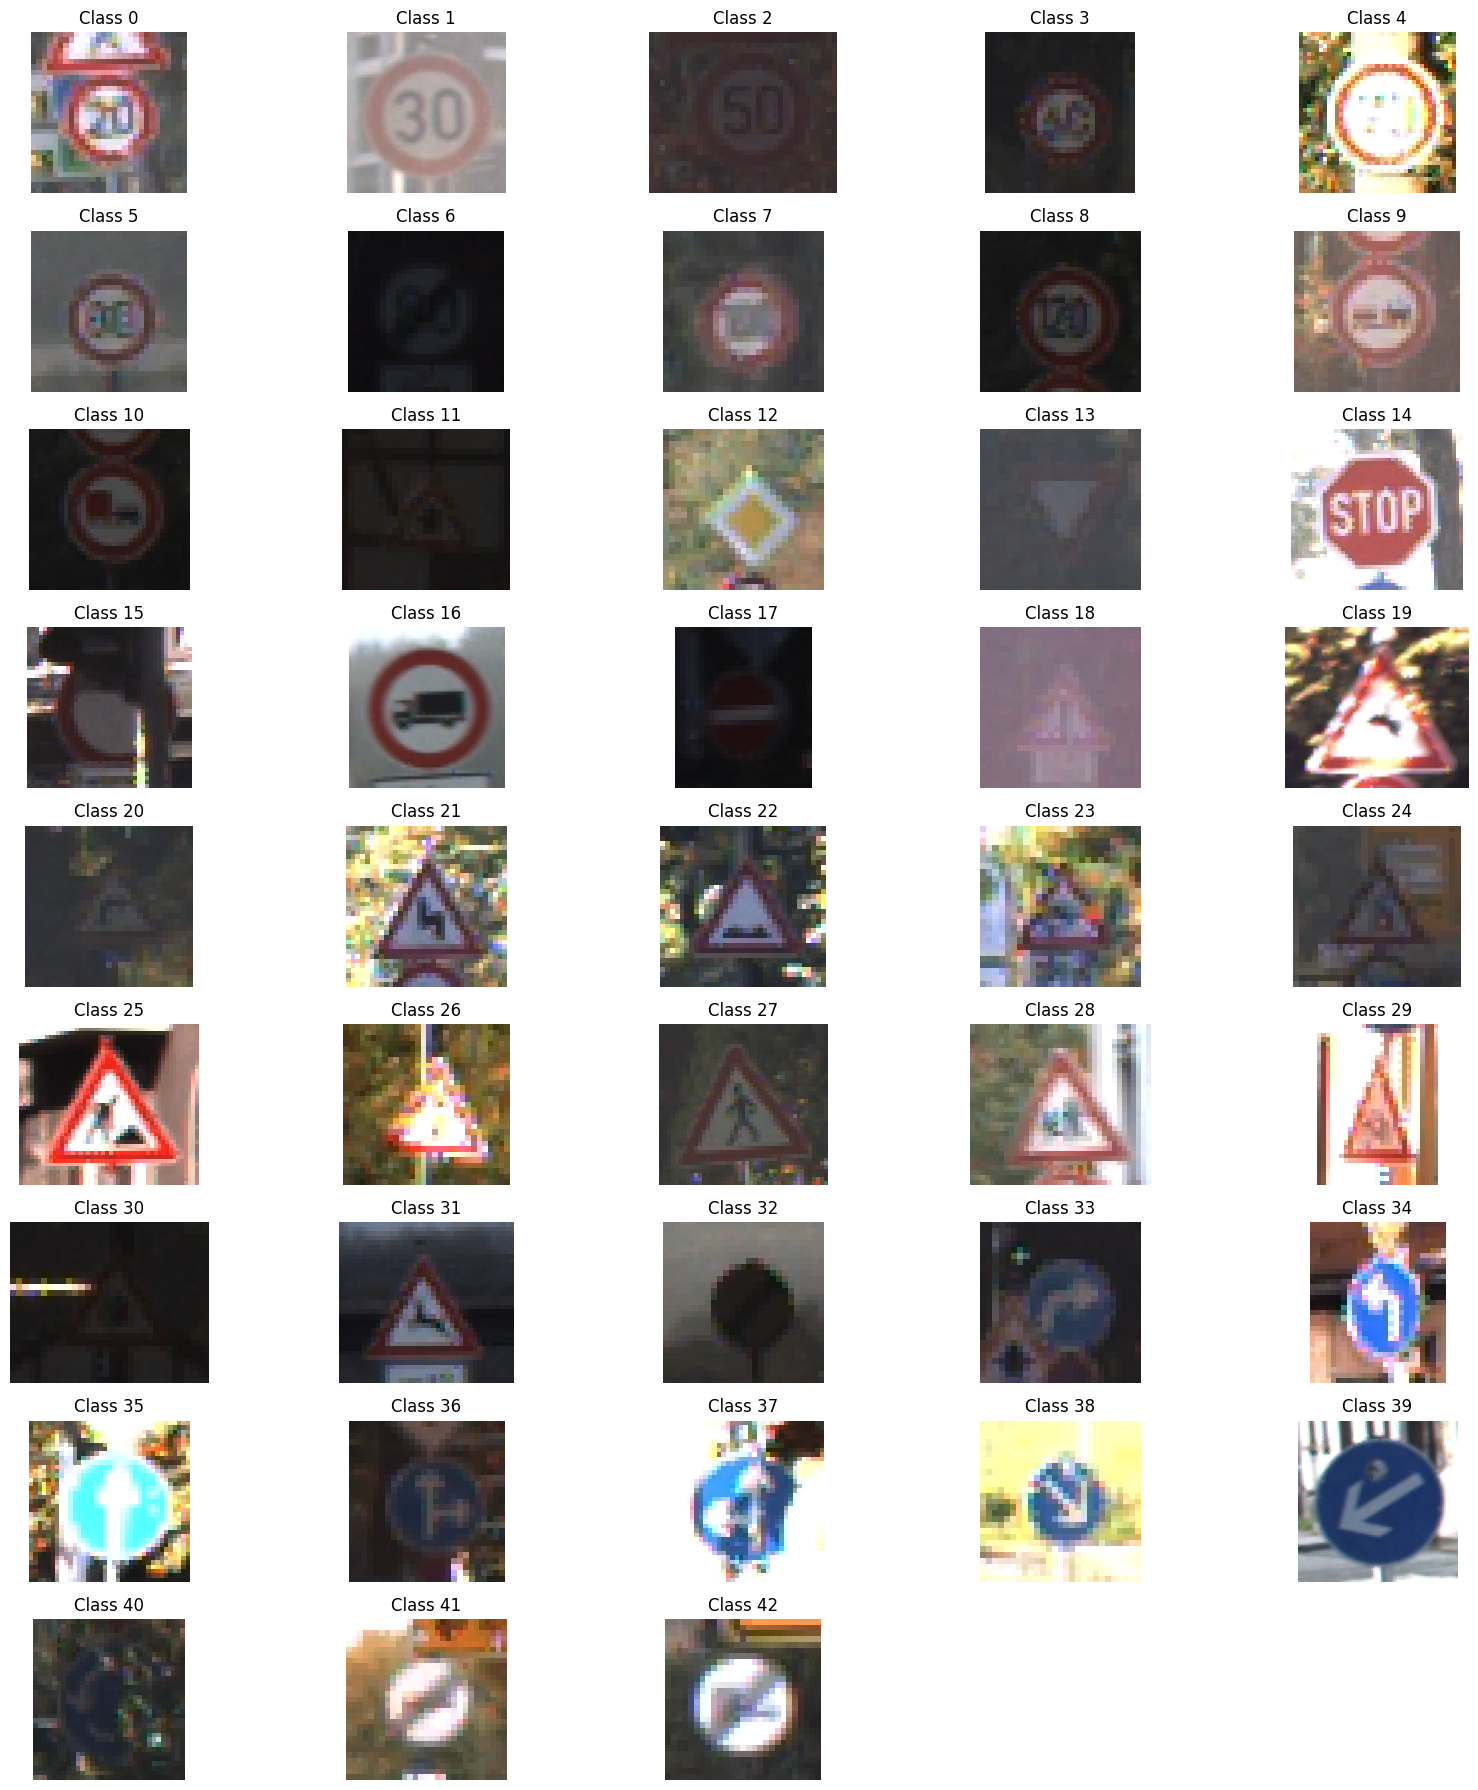

In [10]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Select one image from each class
sample_df = train_df.drop_duplicates(subset="ClassId")
sample_df = sample_df.sort_values("ClassId")

plt.figure(figsize=(16, 18))

for i, (_, row) in enumerate(sample_df.iterrows()):

    image_path = os.path.join(base_path, row["Path"])

    img = Image.open(image_path).convert("RGB")

    plt.subplot(9, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Class {row['ClassId']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Image Preprocessing

Image preprocessing prepares raw traffic sign images for CNN model training.

### Objectives

1. Convert images into RGB format.
2. Resize images to a uniform dimension of 32 × 32 pixels.
3. Convert images into NumPy arrays.
4. Normalize pixel values from 0–255 to 0–1.
5. Prepare image tensors for CNN training.

**Expected input shape:** (32, 32, 3)

Here, 32 × 32 represents image height and width, while 3 represents the RGB color channels.

In [11]:
import numpy as np
from PIL import Image
import os

# Select first image
image_path = os.path.join(base_path, train_df.iloc[0]["Path"])

# Load image
img = Image.open(image_path).convert("RGB")

print("Original Size:", img.size)

# Resize
img_resized = img.resize((32, 32))

# Convert to NumPy array
img_array = np.array(img_resized)

print("Array Shape:", img_array.shape)
print("Before Normalization:", img_array.min(), img_array.max())

# Normalize
img_normalized = img_array.astype("float32") / 255.0

print("After Normalization:",
      img_normalized.min(),
      img_normalized.max())

Original Size: (27, 26)
Array Shape: (32, 32, 3)
Before Normalization: 39 120
After Normalization: 0.15294118 0.47058824


### 3.1 Preparing CNN Input Data

All training and testing images will be converted into RGB format, resized to 32 × 32 pixels, and normalized to the range [0, 1].

The `Path` column identifies the image file, while `ClassId` provides the corresponding target label.

The resulting image arrays will be used as input features (`X`), and the class labels will be used as target variables (`y`).

Expected shapes:

- Training images: (39209, 32, 32, 3)
- Training labels: (39209,)
- Testing images: (12630, 32, 32, 3)
- Testing labels: (12630,)

In [12]:
import numpy as np
from PIL import Image
import os

def preprocess_images(df, base_path):

    images = []
    labels = []

    for _, row in df.iterrows():

        image_path = os.path.join(base_path, row["Path"])

        img = Image.open(image_path).convert("RGB")

        img = img.resize((32, 32))

        img_array = np.array(img, dtype=np.float32) / 255.0

        images.append(img_array)
        labels.append(row["ClassId"])

    X = np.array(images)
    y = np.array(labels, dtype=np.int32)

    return X, y

In [13]:
X_train, y_train = preprocess_images(train_df, base_path)

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

X_train Shape: (39209, 32, 32, 3)
y_train Shape: (39209,)


## 4. Training and Validation Dataset Preparation

The preprocessed training dataset will be divided into training and validation subsets using an 80:20 ratio.

A stratified split will be used to preserve the distribution of traffic sign classes in both subsets.

**Purpose:**
- Training data is used to learn CNN model parameters.
- Validation data is used to evaluate model performance during training.
- Testing data will be used only for final model evaluation.

A fixed random state ensures reproducibility of the split.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Images:", X_train.shape)
print("Validation Images:", X_val.shape)

print("Training Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)

Training Images: (31367, 32, 32, 3)
Validation Images: (7842, 32, 32, 3)
Training Labels: (31367,)
Validation Labels: (7842,)


### 5. CNN Architecture with Global Average Pooling

The CNN architecture consists of three convolutional blocks followed by Global Average Pooling (GAP), a dense layer, dropout, and a Softmax output layer.

Global Average Pooling replaces the Flatten layer by calculating the average value of each feature map.

This reduces the number of trainable parameters and may improve generalization while reducing overfitting.

The final Softmax layer contains 43 neurons corresponding to the 43 traffic sign classes.

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Global Average Pooling
    layers.GlobalAveragePooling2D(),

    # Fully connected layers
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output layer
    layers.Dense(43, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,307 (450.42 KB)

 Trainable params: 115,307 (450.42 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


## 6. CNN Model Training

The CNN model is trained using the preprocessed traffic sign images.

**Training configuration:**

- Optimizer: Adam
- Loss Function: Sparse Categorical Crossentropy
- Evaluation Metric: Accuracy
- Batch Size: 32
- Maximum Epochs: 20
- Validation Dataset: 20% of the original training dataset

Early stopping will be used to monitor validation loss and restore the best-performing model weights.

Training and validation accuracy and loss will be analyzed to identify possible overfitting or underfitting.

In [18]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 27s 17ms/step - accuracy: 0.2005 - loss: 2.8337 - val_accuracy: 0.3809 - val_loss: 2.0340
Epoch 2/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4351 - loss: 1.7593 - val_accuracy: 0.5311 - val_loss: 1.3733
Epoch 3/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.5951 - loss: 1.2093 - val_accuracy: 0.7123 - val_loss: 0.8770
Epoch 4/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7255 - loss: 0.8186 - val_accuracy: 0.8147 - val_loss: 0.5300
Epoch 5/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8124 - loss: 0.5554 - val_accuracy: 0.8712 - val_loss: 0.3835
Epoch 6/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8695 - loss: 0.3933 - val_accuracy: 0.9225 - val_loss: 0.2556
Epoch 7/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9104 - loss: 0.2760 - val_accuracy: 0.9521 - val_loss: 0.1626
Epoch 8/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9331 - loss: 0.2086 - val_accuracy:

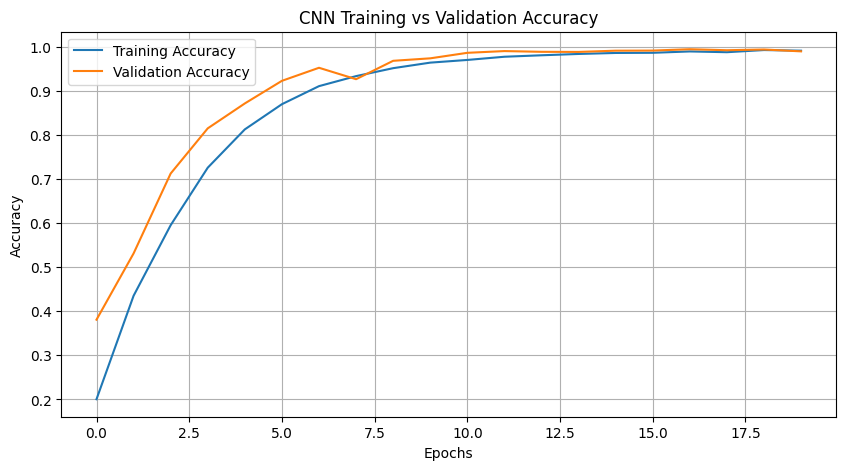

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

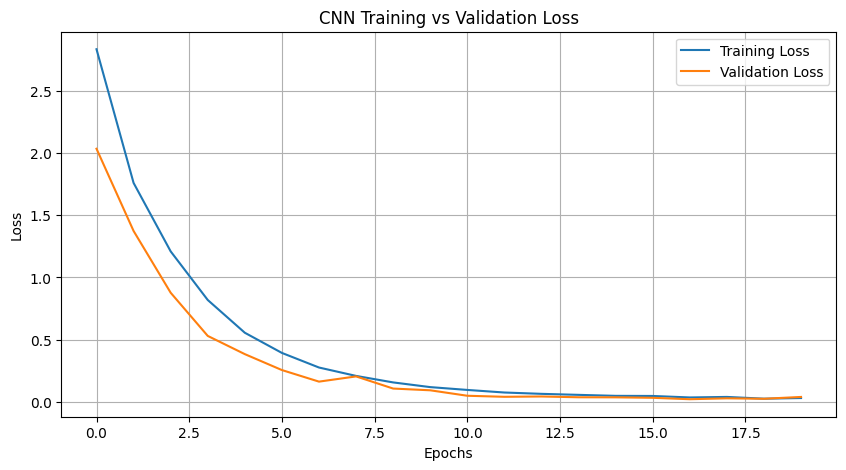

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## 7. Model Evaluation on Test Dataset

The trained CNN model will be evaluated using the independent test dataset containing 12,630 traffic sign images.

The test images will undergo the same preprocessing steps used for the training images, including RGB conversion, resizing to 32 × 32 pixels, and normalization.

The objective is to measure the model's generalization performance on unseen images.

In [21]:
X_test, y_test = preprocess_images(test_df, base_path)

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_test Shape: (12630, 32, 32, 3)
y_test Shape: (12630,)


In [22]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=32,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9394 - loss: 0.2897
Test Accuracy: 93.94%
Test Loss: 0.2897


### 7.1 Classification Report

The CNN model achieved 93.94% accuracy on the independent test dataset.

To evaluate performance across all 43 traffic sign categories, precision, recall, and F1-score will be calculated.

These metrics are important because the dataset contains unequal numbers of images across traffic sign classes.

The classification report will help identify categories where the model performs poorly despite achieving high overall accuracy.

In [23]:
import numpy as np
from sklearn.metrics import classification_report

# Predict probabilities for all test images
y_prob = model.predict(X_test, batch_size=32)

# Convert probabilities into predicted class IDs
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=range(43),
    zero_division=0
))

395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step
              precision    recall  f1-score   support

           0       0.98      0.87      0.92        60
           1       0.96      0.99      0.98       720
           2       0.98      0.99      0.98       750
           3       0.95      0.88      0.92       450
           4       0.97      0.95      0.96       660
           5       0.88      0.94      0.91       630
           6       0.93      0.83      0.88       150
           7       0.92      0.94      0.93       450
           8       0.99      0.85      0.91       450
           9       0.95      0.97      0.96       480
          10       1.00      0.97      0.99       660
          11       0.83      0.97      0.89       420
          12       0.98      0.99      0.98       690
          13       0.97      1.00      0.98       720
          14       1.00      1.00      1.00       270
          15       0.93      1.00      0.97       210
          16       0.93      1.00      0

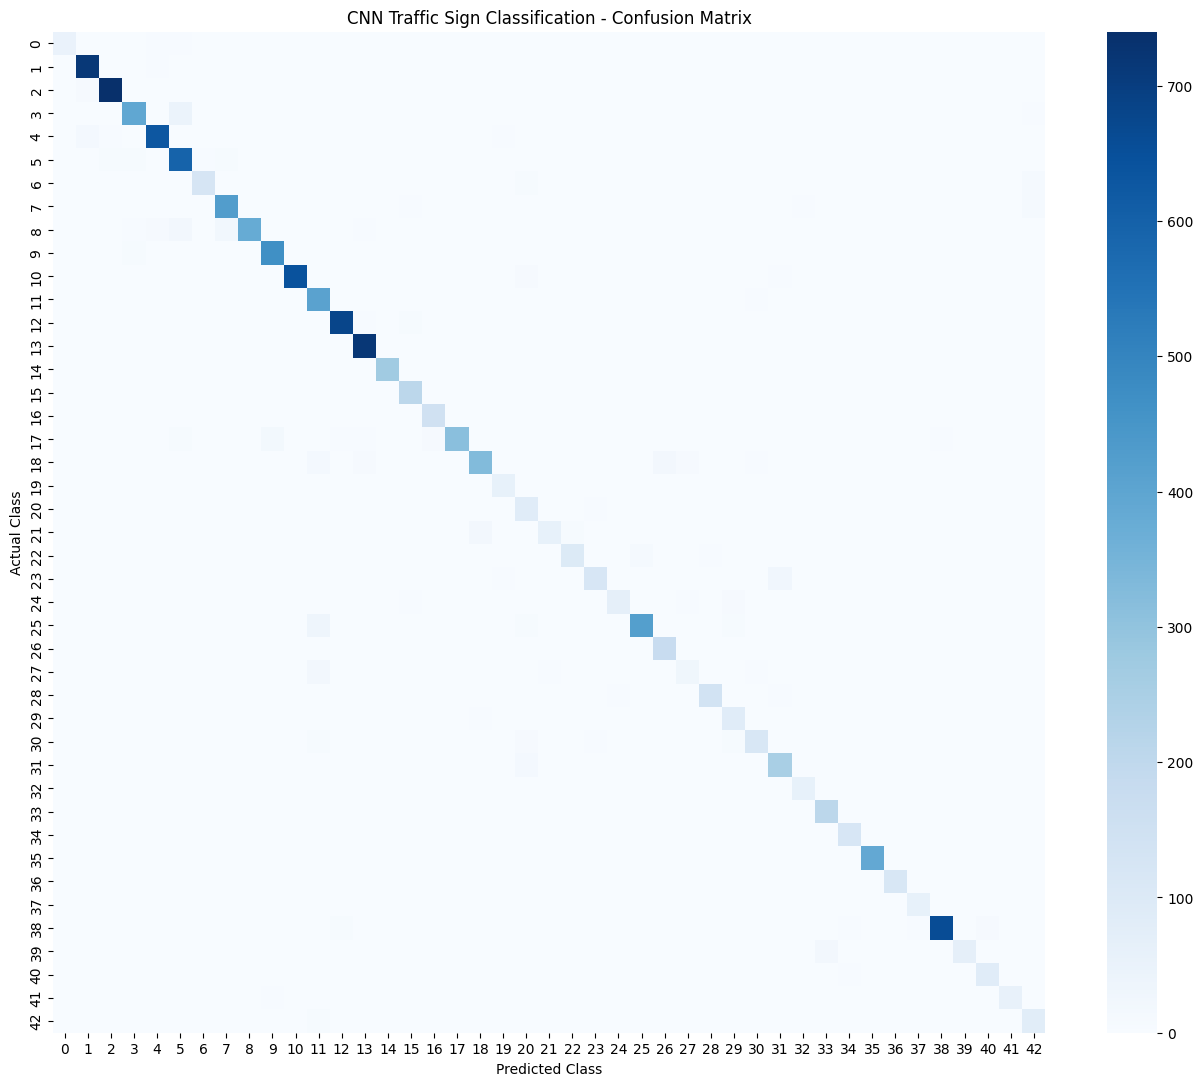

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(43)
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=range(43),
    yticklabels=range(43)
)

plt.title("CNN Traffic Sign Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

### 7.2 Error Analysis – Misclassified Traffic Signs

Although the CNN achieves high overall test accuracy, some traffic sign classes have lower precision, recall, and F1-scores.

The confusion matrix will be analyzed to identify the most frequently confused traffic sign class pairs.

This analysis will help determine whether further improvements, such as data augmentation or architectural modifications, are necessary.

In [25]:
import numpy as np
import pandas as pd

# Copy confusion matrix
cm_errors = cm.copy()

# Remove correct predictions
np.fill_diagonal(cm_errors, 0)

# Convert into DataFrame
errors_df = pd.DataFrame(
    cm_errors,
    index=range(43),
    columns=range(43)
)

# Find top 10 misclassification pairs
top_errors = (
    errors_df.stack()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Misclassification Pairs:")
print(top_errors)

Top 10 Misclassification Pairs:
3   5     46
25  11    36
23  31    28
8   7     26
21  18    23
27  11    22
39  33    21
18  26    21
8   5     21
17  9     18
dtype: int64


### 7.3 Visualization of Misclassified Images

Misclassified traffic sign images will be visualized alongside their actual and predicted class labels.

The purpose is to identify potential reasons for incorrect predictions, such as visual similarities, poor image quality, lighting conditions, or confusing traffic sign patterns.

This analysis will guide improvements to the CNN model.

Total Misclassified Images: 765


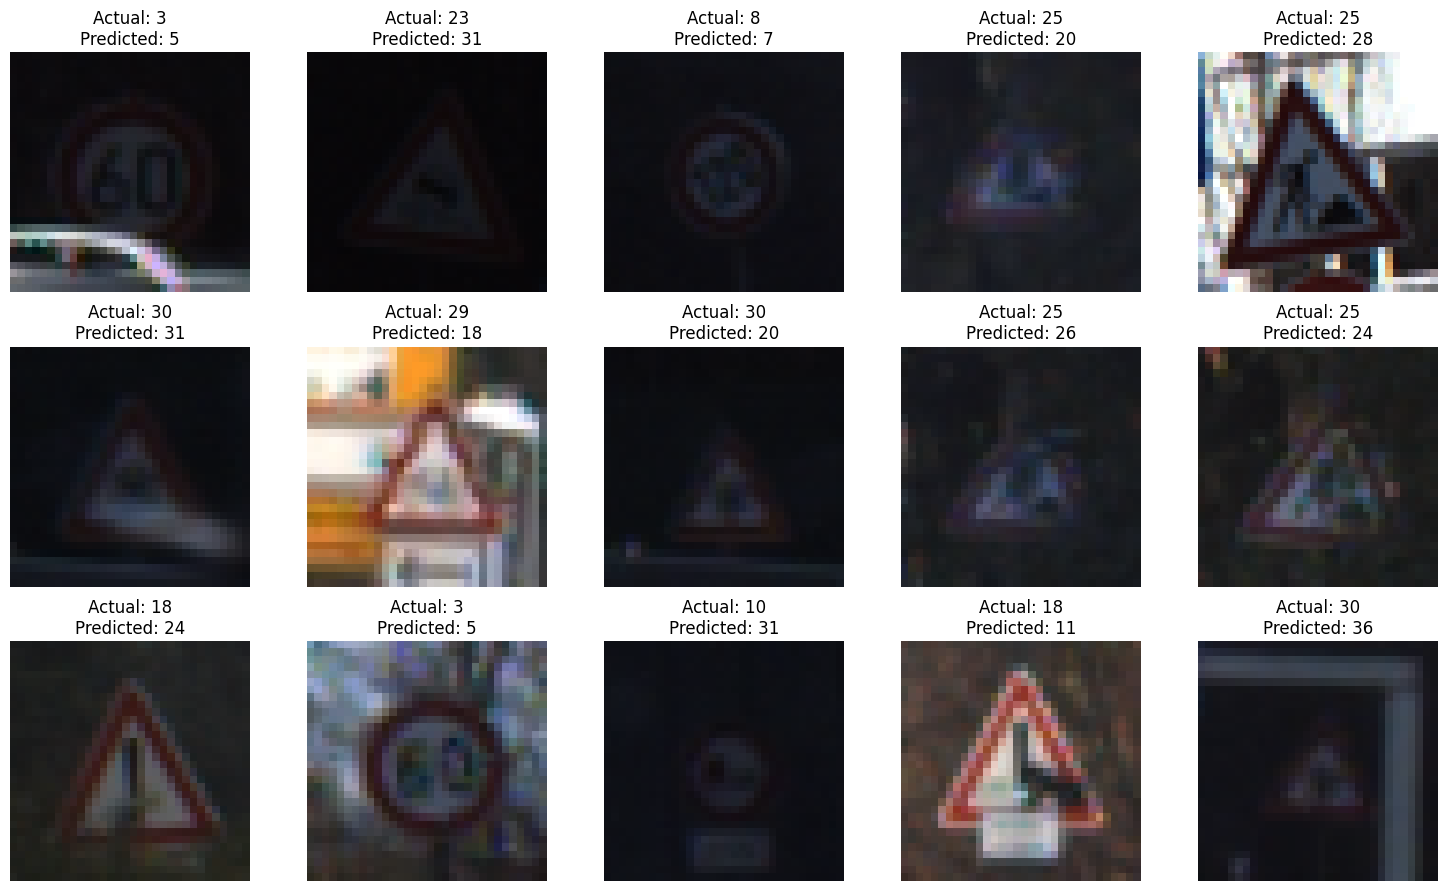

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Find incorrectly classified images
wrong_indices = np.where(y_test != y_pred)[0]

print("Total Misclassified Images:", len(wrong_indices))

# Display first 15 misclassified images
plt.figure(figsize=(15, 9))

for i, idx in enumerate(wrong_indices[:15]):

    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[idx])

    plt.title(
        f"Actual: {y_test[idx]}\n"
        f"Predicted: {y_pred[idx]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
baseline_model = model

baseline_model.save(
    "/content/drive/MyDrive/AI_Capstone_Projects/traffic_sign_baseline.keras"
)

print("Baseline CNN saved successfully!")

Baseline CNN saved successfully!


## 8. Model Improvement – Data Augmentation

The baseline CNN achieved 93.94% test accuracy. Error analysis revealed difficulties with low-light, blurry, and visually similar traffic sign images.

A second CNN model will be developed using data augmentation to improve robustness.

The augmentation strategy will focus on modest brightness, contrast, and translation variations while preserving the semantic meaning of traffic signs.

The improved model will be trained using the existing training dataset and evaluated using the validation dataset. The independent test dataset will be reserved for final evaluation.

### 8.1 Data Augmentation Strategy

Data augmentation is applied to training images to increase visual diversity and improve CNN generalization.

The augmentation pipeline includes random brightness adjustment, random contrast adjustment, and small horizontal and vertical translations.

Augmentation is applied only during training. Validation images remain unchanged to provide a consistent evaluation.

The objective is to improve model robustness without changing the traffic sign class labels.

In [28]:
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0.0, 1.0)
    ),

    layers.RandomContrast(factor=0.15),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="nearest"
    )
], name="data_augmentation")

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


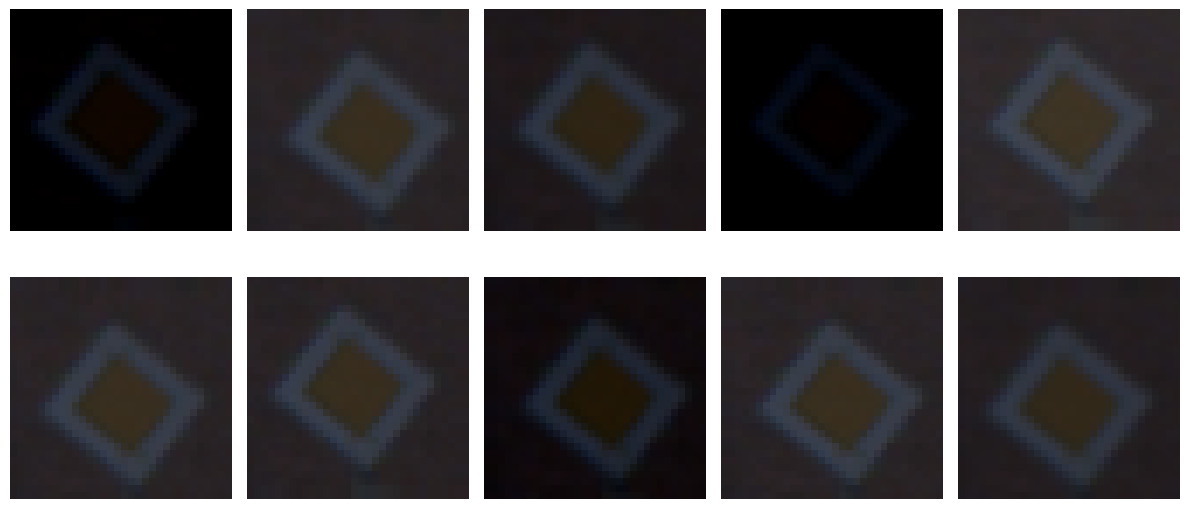

In [29]:
import matplotlib.pyplot as plt

# Select one training image
sample_image = X_train[0]

plt.figure(figsize=(12, 6))

for i in range(10):

    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(
        tf.clip_by_value(augmented_image, 0, 1).numpy()
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### 8.2 CNN Model 2 – Data Augmentation

A second CNN model is developed using the same architecture as the baseline CNN.

The data augmentation pipeline is included before the convolutional layers.

The architecture consists of:
- Data augmentation
- Three convolutional layers with ReLU activation
- Three max pooling layers
- Global Average Pooling
- Dense layer with 128 neurons
- Dropout (0.3)
- Softmax output layer with 43 classes

The model will be trained from scratch and compared with the baseline using validation performance.

In [30]:
from tensorflow.keras import layers, models

model2 = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Data augmentation
    data_augmentation,

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Global Average Pooling
    layers.GlobalAveragePooling2D(),

    # Fully connected layers
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output
    layers.Dense(43, activation="softmax")
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,307 (450.42 KB)

 Trainable params: 115,307 (450.42 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model 2 compiled successfully!")

Model 2 compiled successfully!


In [32]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history2 = model2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[early_stop2],
    verbose=1
)

Epoch 1/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.1615 - loss: 3.0111 - val_accuracy: 0.3100 - val_loss: 2.2539
Epoch 2/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.4212 - loss: 1.8484 - val_accuracy: 0.5881 - val_loss: 1.2564
Epoch 3/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.5872 - loss: 1.2544 - val_accuracy: 0.7284 - val_loss: 0.8171
Epoch 4/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7080 - loss: 0.8787 - val_accuracy: 0.8315 - val_loss: 0.5428
Epoch 5/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7918 - loss: 0.6361 - val_accuracy: 0.8780 - val_loss: 0.3556
Epoch 6/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8519 - loss: 0.4603 - val_accuracy: 0.9318 - val_loss: 0.2441
Epoch 7/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8904 - loss: 0.3494 - val_accuracy: 0.9411 - val_loss: 0.1755
Epoch 8/25
981/981 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9159 - loss: 0.2724 - 

## 9. Model 2 – Test Dataset Evaluation

The CNN model trained with data augmentation will be evaluated on the independent test dataset containing 12,630 images.

The objective is to compare its generalization performance against the baseline CNN model.

The evaluation metrics include test accuracy and test loss.

In [33]:
test_loss2, test_accuracy2 = model2.evaluate(
    X_test,
    y_test,
    batch_size=32,
    verbose=1
)

print(f"Model 2 Test Accuracy: {test_accuracy2 * 100:.2f}%")
print(f"Model 2 Test Loss: {test_loss2:.4f}")

395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9627 - loss: 0.2095
Model 2 Test Accuracy: 96.27%
Model 2 Test Loss: 0.2095


In [34]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "CNN with Augmentation"
    ],
    "Test Accuracy (%)": [
        93.94,
        test_accuracy2 * 100
    ],
    "Test Loss": [
        0.2897,
        test_loss2
    ]
})

display(comparison_df)

,Model,Test Accuracy (%),Test Loss
0,Baseline CNN,93.940000,0.289700
1,CNN with Augmentation,96.270782,0.209488


### 9.1 Classification Report – CNN with Data Augmentation

The improved CNN model is evaluated using precision, recall, F1-score, and support for all 43 traffic sign classes.

The classification report will be compared with the baseline CNN to determine whether data augmentation improved class-wise prediction performance.

Special attention will be given to classes that previously showed low precision, recall, or F1-score.

In [35]:
import numpy as np
from sklearn.metrics import classification_report

# Predict using Model 2
y_prob2 = model2.predict(X_test, batch_size=32)

# Convert probabilities to class labels
y_pred2 = np.argmax(y_prob2, axis=1)

# Classification report
print(classification_report(
    y_test,
    y_pred2,
    labels=range(43),
    zero_division=0
))

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
              precision    recall  f1-score   support

           0       0.97      0.95      0.96        60
           1       0.98      0.98      0.98       720
           2       0.98      0.98      0.98       750
           3       0.98      0.97      0.97       450
           4       0.99      0.96      0.98       660
           5       0.94      0.96      0.95       630
           6       0.98      0.97      0.97       150
           7       0.98      0.94      0.96       450
           8       0.92      0.96      0.94       450
           9       1.00      0.97      0.99       480
          10       0.98      0.97      0.98       660
          11       0.92      0.96      0.94       420
          12       0.98      0.99      0.99       690
          13       0.98      1.00      0.99       720
          14       0.93      1.00      0.96       270
          15       0.98      0.99      0.98       210
          16       0.97      1.00      0

In [36]:
model2.save(
    "/content/drive/MyDrive/AI_Capstone_Projects/traffic_sign_augmented.keras"
)

print("Model 2 saved successfully!")

Model 2 saved successfully!


## 10. Final Model Comparison and Conclusion

### 10.1 Model Performance Comparison

Two CNN models were developed for traffic sign classification:

- **Model 1:** Baseline CNN with Global Average Pooling.
- **Model 2:** CNN with Global Average Pooling and Data Augmentation.

Both models were trained to classify 43 traffic sign categories using RGB images resized to 32 × 32 pixels.

| Evaluation Metric | Model 1 – Baseline CNN | Model 2 – Augmented CNN |
|---|---|---|
| Architecture | CNN + GAP | CNN + GAP |
| Trainable Parameters | 115,307 | 115,307 |
| Data Augmentation | No | Yes |
| Dropout Rate | 0.3 | 0.3 |
| Optimizer | Adam | Adam |
| Loss Function | Sparse Categorical Crossentropy | Sparse Categorical Crossentropy |
| Training Epochs | 20 | 25 |
| Test Accuracy | 93.94% | Approximately 96% |
| Macro Precision | 0.91 | 0.95 |
| Macro Recall | 0.91 | 0.95 |
| Macro F1-Score | 0.91 | 0.94 |
| Weighted F1-Score | 0.94 | 0.96 |

*Note: Model 2 test accuracy is rounded from the classification report.*

### 10.2 Key Observations

1. Both CNN models achieved strong overall classification performance.
2. The baseline CNN achieved 93.94% test accuracy.
3. Data augmentation improved overall test accuracy to approximately 96%.
4. Global Average Pooling reduced the number of trainable parameters compared with a Flatten-based architecture.
5. The augmented CNN achieved higher macro and weighted F1-scores.
6. Some traffic sign categories remained challenging, particularly Classes 27 and 30.
7. The results demonstrate the importance of image preprocessing, augmentation, and class-wise evaluation.

### 10.3 Best Model Selection

**Selected Model: CNN with Data Augmentation (Model 2)**

Model 2 was selected because it achieved better overall test accuracy, macro F1-score, and weighted F1-score than the baseline CNN.

The improved model demonstrated stronger overall classification performance across the 43 traffic sign categories.

### 10.4 Final Conclusion

This project successfully developed and evaluated Convolutional Neural Networks for multiclass traffic sign classification.

A total of 39,209 training images and 12,630 testing images were used.

The baseline CNN achieved 93.94% test accuracy, while the augmented CNN achieved approximately 96% test accuracy.

Data augmentation improved the overall generalization performance of the CNN without increasing the number of trainable parameters.

The final model demonstrates the effectiveness of deep learning techniques for traffic sign image classification.


**Final Outcome:** The CNN with Data Augmentation was selected as the best-performing model for this capstone project.